---

digital brain MEG pipeline

---

In [1]:
# autoload
%load_ext autoreload
%autoreload 2

# load pgl actions
from pgl import pglActions, pglActionsMNE, pglStorage, pgl, pglSession
#pgl = pgl()

---

Add Xan's mSSS Foster's functions

---

In [ ]:
#Install Xan's mSSS/Foster's functions
#!/usr/bin/env python3
# -*- coding: utf-8 -*-
"""
Created on Wed Jul 29 15:17:10 2026

@author: Alexandria McPherson

Rewriting all the MATLAB functions involved in mSSS into Python
Original MATLAB functions written  by Samu Taulu and Alexandria McPherson
"""

import numpy as np
from scipy.special import lpmv
import mne


def spharm(theta, phi, l, m):
    """
    Compute spherical harmonics Y_l^m(theta, phi)
    
    Parameters:
    -----------
    theta : float or array
        Polar angle (colatitude)
    phi : float or array
        Azimuthal angle
    l : int
        Degree (l >= 0)
    m : int
        Order (-l <= m <= l)
    
    Returns:
    --------
    Y : complex float or array
        Spherical harmonics
    """
    # Compute normalization factor
    scale = np.sqrt((2*l + 1) * np.prod(np.arange(1, l - m + 1)) / 
                    (4 * np.pi * np.prod(np.arange(1, l + m + 1))))
    
    if m < 0:
        # For negative m
        abs_m = abs(m)
        p = lpmv(abs_m, l, np.cos(theta))
        Y = scale * ((-1)**abs_m) * (np.prod(np.arange(1, l - abs_m + 1)) / 
                                      np.prod(np.arange(1, l + abs_m + 1))) * p
    elif m > 0:
        # For positive m
        p = lpmv(m, l, np.cos(theta))
        Y = scale * p
    else:
        # For m = 0
        p = lpmv(0, l, np.cos(theta))
        Y = scale * p
    
    # Multiply by complex exponential e^(i*m*phi)
    Y = Y * (np.cos(m * phi) + 1j * np.sin(m * phi))
    
    return Y


def vsh_modified_out(theta, phi, l, m):
    """
    Vector spherical harmonic function modified from Hill's function
    W_lm for quantum numbers l and m. Angles theta and phi should be
    given in radians.
    
    Parameters:
    -----------
    theta : float or array
        Polar angle (colatitude) in radians
    phi : float or array
        Azimuthal angle in radians
    l : int
        Degree (l >= 0)
    m : int
        Order (-l <= m <= l)
    
    Returns:
    --------
    Wm : numpy array of length 3
        Vector spherical harmonic external components [Wm1, Wm2, Wm3]
    """
    
    scale = 1
    scale_sph = ((-1)**m * np.sqrt((2*l + 1) * np.prod(np.arange(1, l - m + 1)) / 
                                    (4 * np.pi * np.prod(np.arange(1, l + m + 1)))))
    
    scale_minus = 1 / ((-1)**(m - 1) * np.sqrt((2*l + 1) * 
                                                np.prod(np.arange(1, l - (m - 1) + 1)) / 
                                                (4 * np.pi * np.prod(np.arange(1, l + (m - 1) + 1)))))
    
    scale_plus = 1 / ((-1)**(m + 1) * np.sqrt((2*l + 1) * 
                                               np.prod(np.arange(1, l - (m + 1) + 1)) / 
                                               (4 * np.pi * np.prod(np.arange(1, l + (m + 1) + 1)))))
    
    # Compute spherical harmonics
    Y = spharm(theta, phi, l, m)
    
    if m > -l:
        Yminus = spharm(theta, phi, l, m - 1)
    else:
        Yminus = 0
    
    if m < l:
        Yplus = spharm(theta, phi, l, m + 1)
    else:
        Yplus = 0
    
    # Compute dY/dtheta
    dY = (0.5 * scale_sph * 
          ((l + m) * (l - m + 1) * scale_minus * Yminus * 
           (np.cos(phi) + 1j * np.sin(phi)) - 
           scale_plus * Yplus * (np.cos(-phi) + 1j * np.sin(-phi))))
    
    # Prevent division by zero
    if np.isscalar(theta):
        if theta == 0:
            theta = np.finfo(float).eps
    else:
        theta = np.where(theta == 0, np.finfo(float).eps, theta)
    
    # Compute vector components
    Wm = np.zeros(3, dtype=complex)
    Wm[0] = scale * l * Y
    Wm[1] = scale * dY
    Wm[2] = scale * (1j * m / np.sin(theta)) * Y
    
    return Wm


def vsh_modified_in(theta, phi, l, m):
    """
    Vector spherical harmonic function modified from Hill's function
    V_lm for quantum numbers l and m. Angles theta and phi should be
    given in radians.
    
    Parameters:
    -----------
    theta : float or array
        Polar angle (colatitude) in radians
    phi : float or array
        Azimuthal angle in radians
    l : int
        Degree (l >= 0)
    m : int
        Order (-l <= m <= l)
    
    Returns:
    --------
    Vm : numpy array of length 3
        Vector spherical harmonic interior components [Vm1, Vm2, Vm3]
    """
    
    scale = 1
    scale_sph = ((-1)**m * np.sqrt((2*l + 1) * np.prod(np.arange(1, l - m + 1)) / 
                                    (4 * np.pi * np.prod(np.arange(1, l + m + 1)))))
    
    scale_minus = 1 / ((-1)**(m - 1) * np.sqrt((2*l + 1) * 
                                                np.prod(np.arange(1, l - (m - 1) + 1)) / 
                                                (4 * np.pi * np.prod(np.arange(1, l + (m - 1) + 1)))))
    
    scale_plus = 1 / ((-1)**(m + 1) * np.sqrt((2*l + 1) * 
                                               np.prod(np.arange(1, l - (m + 1) + 1)) / 
                                               (4 * np.pi * np.prod(np.arange(1, l + (m + 1) + 1)))))
    
    # Compute spherical harmonics
    Y = spharm(theta, phi, l, m)
    
    if m > -l:
        Yminus = spharm(theta, phi, l, m - 1)
    else:
        Yminus = 0
    
    if m < l:
        Yplus = spharm(theta, phi, l, m + 1)
    else:
        Yplus = 0
    
    # Compute dY/dtheta
    dY = (0.5 * scale_sph * 
          ((l + m) * (l - m + 1) * scale_minus * Yminus * 
           (np.cos(phi) + 1j * np.sin(phi)) - 
           scale_plus * Yplus * (np.cos(-phi) + 1j * np.sin(-phi))))
    
    # Prevent division by zero
    if np.isscalar(theta):
        if theta == 0:
            theta = np.finfo(float).eps
    else:
        theta = np.where(theta == 0, np.finfo(float).eps, theta)
    
    # Compute vector components
    Vm = np.zeros(3, dtype=complex)
    Vm[0] = scale * (-(l + 1)) * Y
    Vm[1] = scale * dY
    Vm[2] = scale * (1j * m / np.sin(theta)) * Y
    
    return Vm

def Sin_vsh_vv(r_sphere, R, EX, EY, EZ, ch_types, Lin):
    """
    Calculate the internal SSS basis Sin using vector spherical harmonics
    
    Parameters:
    -----------
    r_sphere : numpy array of shape (3,)
        Sphere center position
    R : numpy array of shape (3, nchan)
        Sensor positions
    EX : numpy array of shape (3, nchan)
        X-direction unit vectors for sensors
    EY : numpy array of shape (3, nchan)
        Y-direction unit vectors for sensors
    EZ : numpy array of shape (3, nchan)
        Z-direction unit vectors for sensors
    ch_types : numpy array of length nchan
        Channel types (0 for GRAD, 1 for MAG)
    Lin : int
        Maximum degree for spherical harmonics
    
    Returns:
    --------
    Sin : numpy array of shape (nchan, nbasis)
        SSS basis matrix
    SNin : numpy array of shape (nchan, nbasis)
        Normalized SSS basis matrix
    """
    
    MAG = 1
    GRAD = 0
    mu0 = 1.25664e-6  # Permeability of vacuum
    
    # For numerical surface integration:
    mag_size = 21e-3
    baseline = 16.69e-3
    d = np.sqrt(3/5) * mag_size / 2
    dx1 = 5.89e-3
    dx2 = 10.8e-3
    dy = 6.71e-3
    
    Dmag = np.array([[0, d, -d, -d, d, 0, 0, d, -d],
                     [0, d, d, -d, -d, d, -d, 0, 0]])
    
    Dgrad = np.array([[dx1, dx2, dx1, dx2, -dx1, -dx2, -dx1, -dx2],
                      [dy, dy, -dy, -dy, dy, dy, -dy, -dy]])
    
    weights_mag = np.array([16/81, 25/324, 25/324, 25/324, 25/324, 
                            10/81, 10/81, 10/81, 10/81])
    
    weights_grad = np.zeros(8)
    for j in range(8):
        if j < 4:
            weights_grad[j] = 1 / (4 * baseline)
        else:
            weights_grad[j] = -1 / (4 * baseline)
    
    nchan = len(ch_types)
    nbasis = sum(2*l + 1 for l in range(1, Lin + 1))
    Sin = np.zeros((nchan, nbasis), dtype=complex)
    
    for ch in range(nchan):
        count = 0
        R_ch = R[:, ch] - r_sphere
        
        if ch_types[ch] == GRAD:
            D = Dgrad
            weights = weights_grad
        elif ch_types[ch] == MAG:
            D = Dmag
            weights = weights_mag
        else:
            raise ValueError('Unknown sensor type!')
        
        for l in range(1, Lin + 1):
            for m in range(-l, l + 1):
                Sin[ch, count] = -mu0 * _vsh_response_in(R_ch, EX[:, ch], EY[:, ch], 
                                                      EZ[:, ch], D, weights, l, m)
                count += 1
    
    # Scale magnetometer channels by 100
    for i in range(Sin.shape[0]):
        if ch_types[i] == 1:
            Sin[i, :] = Sin[i, :] * 100
    
    # Normalize columns
    SNin = np.zeros_like(Sin)
    for j in range(Sin.shape[1]):
        col_norm = np.linalg.norm(Sin[:, j])
        if col_norm > 0:  # Check for zero norm to avoid division by zero
            SNin[:, j] = Sin[:, j] / col_norm
        else:
            SNin[:, j] = Sin[:, j]  # Keep as zero or handle differently
        
    return Sin, SNin


def _vsh_response_in(r, ex, ey, ez, D, weights, l, m):
    """
    Helper function to compute internal VSH for a single sensor
    
    Parameters:
    -----------
    r : numpy array of shape (3,)
        Sensor position (relative to sphere center)
    ex, ey, ez : numpy array of shape (3,)
        Sensor orientation unit vectors
    D : numpy array of shape (2, npoints)
        Integration point offsets
    weights : numpy array of length npoints
        Integration weights
    l : int
        Spherical harmonic degree
    m : int
        Spherical harmonic order
    
    Returns:
    --------
    Sin_element : complex float
        VSH expansion
    """
    
    npoints = len(weights)
    V = np.zeros((3, npoints), dtype=complex)
    
    for j in range(npoints):
        r_this = r + D[0, j] * ex + D[1, j] * ey
        rn = np.linalg.norm(r_this)
        theta = np.arccos(r_this[2] / rn)
        phi = np.arctan2(r_this[1], r_this[0])
        
        sint = np.sin(theta)
        sinp = np.sin(phi)
        cost = np.cos(theta)
        cosp = np.cos(phi)
        
        vs = vsh_modified_in(theta, phi, l, m) / rn**(l + 2)
        
        V[0, j] = vs[0] * sint * cosp + vs[1] * cost * cosp - vs[2] * sinp
        V[1, j] = vs[0] * sint * sinp + vs[1] * cost * sinp + vs[2] * cosp
        V[2, j] = vs[0] * cost - vs[1] * sint
    
    Sin_element = np.dot(V @ weights, ez)
    return Sin_element


def Sout_vsh_vv(r_sphere, R, EX, EY, EZ, ch_types, Lout):
    """
    Calculate the external SSS basis Sout using vector spherical harmonics
    
    Parameters:
    -----------
    r_sphere : numpy array of shape (3,)
        Sphere center position
    R : numpy array of shape (3, nchan)
        Sensor positions
    EX : numpy array of shape (3, nchan)
        X-direction unit vectors for sensors
    EY : numpy array of shape (3, nchan)
        Y-direction unit vectors for sensors
    EZ : numpy array of shape (3, nchan)
        Z-direction unit vectors for sensors
    ch_types : numpy array of length nchan
        Channel types (0 for GRAD, 1 for MAG)
    Lout : int
        Maximum degree for spherical harmonics
    
    Returns:
    --------
    Sout : numpy array of shape (nchan, nbasis)
        SSS basis matrix
    SNout : numpy array of shape (nchan, nbasis)
        Normalized SSS basis matrix
    """
    
    MAG = 1
    GRAD = 0
    mu0 = 1.25664e-6  # Permeability of vacuum
    
    # For numerical surface integration:
    mag_size = 21e-3
    baseline = 16.69e-3
    d = np.sqrt(3/5) * mag_size / 2
    dx1 = 5.89e-3
    dx2 = 10.8e-3
    dy = 6.71e-3
    
    Dmag = np.array([[0, d, -d, -d, d, 0, 0, d, -d],
                     [0, d, d, -d, -d, d, -d, 0, 0]])
    
    Dgrad = np.array([[dx1, dx2, dx1, dx2, -dx1, -dx2, -dx1, -dx2],
                      [dy, dy, -dy, -dy, dy, dy, -dy, -dy]])
    
    weights_mag = np.array([16/81, 25/324, 25/324, 25/324, 25/324, 
                            10/81, 10/81, 10/81, 10/81])
    
    weights_grad = np.zeros(8)
    for j in range(8):
        if j < 4:
            weights_grad[j] = 1 / (4 * baseline)
        else:
            weights_grad[j] = -1 / (4 * baseline)
    
    nchan = len(ch_types)
    nbasis = sum(2*l + 1 for l in range(1, Lout + 1))
    Sout = np.zeros((nchan, nbasis), dtype=complex)
    
    for ch in range(nchan):
        count = 0
        R_ch = R[:, ch] - r_sphere
        
        if ch_types[ch] == GRAD:
            D = Dgrad
            weights = weights_grad
        elif ch_types[ch] == MAG:
            D = Dmag
            weights = weights_mag
        else:
            raise ValueError('Unknown sensor type!')
        
        for l in range(1, Lout + 1):
            for m in range(-l, l + 1):
                Sout[ch, count] = -mu0 * _vsh_response_out(R_ch, EX[:, ch], EY[:, ch], 
                                                       EZ[:, ch], D, weights, l, m)
                count += 1
    
    # Scale magnetometer channels by 100
    for i in range(Sout.shape[0]):
        if ch_types[i] == 1:  # every third is a magnetometer
            Sout[i, :] = Sout[i, :] * 100
    
    # Normalize columns
    SNout = np.zeros_like(Sout)
    for j in range(Sout.shape[1]):
        col_norm = np.linalg.norm(Sout[:, j])
        if col_norm > np.finfo(float).eps:
            SNout[:, j] = Sout[:, j] / col_norm
        else:
            SNout[:, j] = 0
    
    return Sout, SNout


def _vsh_response_out(r, ex, ey, ez, D, weights, l, m):
    """
    Helper function to compute external VSH for a single sensor
    
    Parameters:
    -----------
    r : numpy array of shape (3,)
        Sensor position (relative to sphere center)
    ex, ey, ez : numpy array of shape (3,)
        Sensor orientation unit vectors
    D : numpy array of shape (2, npoints)
        Integration point offsets
    weights : numpy array of length npoints
        Integration weights
    l : int
        Spherical harmonic degree
    m : int
        Spherical harmonic order
    
    Returns:
    --------
    Sout_element : complex float
        VSH response value
    """
    
    npoints = len(weights)
    W = np.zeros((3, npoints), dtype=complex)
    
    for j in range(npoints):
        r_this = r + D[0, j] * ex + D[1, j] * ey
        rn = np.linalg.norm(r_this)
        theta = np.arccos(r_this[2] / rn)
        phi = np.arctan2(r_this[1], r_this[0])
        
        sint = np.sin(theta)
        sinp = np.sin(phi)
        cost = np.cos(theta)
        cosp = np.cos(phi)
        
        ws = vsh_modified_out(theta, phi, l, m) * rn**(l - 1)
        
        W[0, j] = ws[0] * sint * cosp + ws[1] * cost * cosp - ws[2] * sinp
        W[1, j] = ws[0] * sint * sinp + ws[1] * cost * sinp + ws[2] * cosp
        W[2, j] = ws[0] * cost - ws[1] * sint
    
    Sout_element = np.dot(W @ weights, ez)
    
    return Sout_element

def _fosters_inverse(S,N,phi_0):
    """
    Parameters
    ----------
    S : matrix nchan x vectors
        either SSS or mSSS
    N : 2D square matrix, (number of sensors) X (number of sensors)
        Sensor noise covariance matrix, calculated using empircial covariance
        implemented in mne.compute_raw_covariance

    Returns
    -------
    data_fosters : 2D matrix, (number of sensors) X (time)
        Matrix containing data corresponding to each MEG channel over time after
        reconstruction with Fosters Inverse preprocessing
    """
    ## setup Foster's Inverse- calculate Matrix B and vector b
    pS= np.linalg.pinv(S)
    XN = pS @ phi_0
    alpha = np.transpose(XN)
    alpha_cov_norm = np.cov(XN)
    S_star = np.transpose(np.conj(S))
    first = np.linalg.pinv(S@alpha_cov_norm@S_star +N)
    B = alpha_cov_norm @ S_star @ first
    m_alpha = np.transpose(np.mean(alpha,0))
    b = m_alpha - B@S@m_alpha
    x_bar = np.zeros_like(XN)
    
    ## calculate Foster's Inverse estimate of multipole moments
    for i in range(0,np.shape(phi_0)[1]):
        x_bar[:,i]=B@phi_0[:,i] + b
    
    ## use new estimate to reconstruct internal data
    data_fosters = np.real(S@x_bar)
    return data_fosters


def apply_preprocessing(center1, center2, raw, do_fos, Ntmin, Ntmax, do_msss, ch_types, Lin, Lout):
    """
    Calculate two-origin mSSS basis
    Modified from Matlab Xan McPherson, 2024
    
    Give two centers, code calculates two SSS expansions, then combines them
    based on eSSS and SVD concatenation
    
    Parameters:
    -----------
    center1, center2 : numpy array of shape (3,)
        (x,y,z) locations of expansion centers
        returned by function FIT_SPHERES_TO_MRI
    raw: MNE.RAW data structure
        ensure BADS are marked and dropped
    do_fos: bool
    Ntmin, Ntmax: int
        time start and end (in seconds) to use for noise covariance calculation
        leave as None if "do_fos=FALSE"
    do_msss: bool
        do_fos=TRUE and do_msss=TRUE will execute Fosters Inverse with mSSS and empirical N 
        do_fos=FALSE and do_msss=TRUE will execute mSSS
        do_fos=TRUE and do_msss=FALSE will execute Fosters Inverse with SSS and empirical N 
    ch_types : numpy array of length nchan
        Vector of 1's for magnetometers, 0's for gradiometers
    Lin, Lout : int
        VSH truncation order, typically (8, 3)
    
    Returns:
    --------
    raw_msss: MNE.RAW data structure
        raw data structure after mSSS preprocessing
    """
    if do_msss == False and do_fos==False:
        print("Incompatible combination of Foster's Inverse with SSS, with mSSS, or mSSS alone. See prompt inscructions")
        return

    ## create data strcutre, indicates in "info" that some preprocessing akin to SSS has happened
    raw_preprocessed = mne.preprocessing.maxwell_filter(raw, origin=(0.,0.,0.), int_order=Lin, ext_order=Lout, calibration=None, coord_frame='meg', regularize='in', ignore_ref=True, bad_condition='error', mag_scale=100.0, extended_proj=(), verbose=None)  # just to get the info to indicate some Maxwell filtering was done etc.
    assert raw.info["bads"] == [] # double check bads were dropped
    meg_picks = mne.pick_types(raw.info, meg=True)
    phi_0 = raw.get_data(picks='meg')
    
    if do_msss == True:
        ## get chan positions
        # these are in DEVICE COORDS
        # before change Sep 19 2026: issue is if EOG channel added but with no sensor geometry.
        # fixed by restricting mSSS calculation to actual MEG channels
        R=np.zeros([3,len(meg_picks)])
        EX=np.zeros([3,len(meg_picks)])
        EY=np.zeros([3,len(meg_picks)])
        EZ=np.zeros([3,len(meg_picks)])
        for i, pick in enumerate(meg_picks):
            R[:,i] = np.transpose(raw.info["chs"][pick]["loc"][:3])
            EX[:,i] = np.transpose(raw.info["chs"][pick]["loc"][3:6])
            EY[:,i] = np.transpose(raw.info["chs"][pick]["loc"][6:9])
            EZ[:,i] = np.transpose(raw.info["chs"][pick]["loc"][9:12])
        
        ## transform into HEAD COORDS
        dev_head_t = raw.info["dev_head_t"]["trans"]
        RT = np.matmul(dev_head_t,np.vstack([R, np.ones(np.shape(R)[1])]))[:-1]
        EXT = np.matmul(dev_head_t[:3, :3], EX)
        EYT = np.matmul(dev_head_t[:3, :3], EY)
        EZT = np.matmul(dev_head_t[:3, :3], EZ)
    
        
        # Calculate single VSH expansions from two optimized origins
        _, SNin1 = Sin_vsh_vv(center1, RT, EXT, EYT, EZT, ch_types, Lin)
        _, SNin2 = Sin_vsh_vv(center2, RT, EXT, EYT, EZT, ch_types, Lin)
        
        # Combine VSH expansions into one interior basis
        combined = np.concatenate([SNin1, SNin2], axis=1)
        U, sig_num, _ = np.linalg.svd(combined, full_matrices=True)
        
        # Keep vectors over a significance value > thresh
        thresh = 0.005
        ratio = sig_num / sig_num[0]
        significant_indices = np.where(ratio >= thresh)[0]
        SNin_tot = U[:, significant_indices]
        
        # Calculate exterior VSH basis at origin of system
        _, SNout = Sout_vsh_vv(np.array([0, 0, 0]), R, EX, EY, EZ, ch_types, Lout)
        #S=np.concatenate([SNin_tot,SNout],axis=1)
        S=SNin_tot
        if do_msss == True and do_fos==True:
            ## foster's inverse with mSSS
            N = mne.compute_raw_covariance(raw,tmin=Ntmin,tmax=Ntmax,rank="info",method='empirical')["data"]
            data_fosters= _fosters_inverse(S, N, phi_0)
            ## put new Foster's inverse with mSSS data "raw" structure
            raw_preprocessed._data[meg_picks] = data_fosters
        elif do_msss == True and do_fos==False: 
            ## just mSSS
            pS = np.linalg.pinv(S)
            XN = pS @ phi_0
            data_msss = np.real(S@XN)
            ## put new mSSS data "raw" structure
            raw_preprocessed._data[meg_picks] = data_msss
   
    elif do_msss==False and do_fos==True:
        ## do Foster's Inverse with SSS
        [S, pS, reg_moments, n_use_in]=mne.preprocessing.compute_maxwell_basis(raw.info, origin=(0.,0.,0.), int_order=Lin, ext_order=Lout, calibration=None, coord_frame='meg', regularize=None, ignore_ref=True, bad_condition='ignore', mag_scale=100.0, extended_proj=(), verbose=None)
        N = mne.compute_raw_covariance(raw,tmin=Ntmin,tmax=Ntmax,rank="info",method='empirical')["data"]
        data_fosters= _fosters_inverse(S[:, :n_use_in], N, phi_0)
        ## put new Foster's with SSS data "raw" structure
        raw_preprocessed._data[meg_picks] = data_fosters
            
    return raw_preprocessed
    
def apply_preprocessing_run_window(center1, center2, raw, do_fos, Ntmin, Ntmax, do_msss, ch_types, Lin, Lout, run_tmin=None, run_tmax=None, diagnostics=None):
    """
    Calculate two-origin mSSS basis and/or Foster's inverse on one segment of raw.
    Modified from Matlab Xan McPherson, 2024

    Parameters:
    -----------
    center1, center2 : numpy array of shape (3,)
        (x,y,z) locations of expansion centers (from FIT_SPHERES_TO_MRI)
    raw : MNE.RAW data structure (preloaded)
        BADS must be dropped. Samples outside the run window are returned
        exactly as recorded.
    do_fos : bool
    Ntmin, Ntmax : float or None
        Noise covariance window, in seconds on raw.times (0 = first sample of raw).
        Computed from the FULL raw, so the window may lie outside the run window.
        Only used if do_fos=True. None/None means the whole recording.
    do_msss : bool
        do_fos=True,  do_msss=True  -> Foster's Inverse with mSSS and empirical N
        do_fos=False, do_msss=True  -> mSSS alone
        do_fos=True,  do_msss=False -> Foster's Inverse with SSS and empirical N
        do_fos=False, do_msss=False -> not supported
    ch_types : numpy array, one entry per MEG channel (1 = mag, 0 = grad)
    Lin, Lout : int
        VSH truncation order, typically (8, 3)
    run_tmin, run_tmax : float or None
        Segment to process, in seconds on raw.times. None means start/end of raw.
        run_tmax is exclusive.

    Returns:
    --------
    raw_preprocessed : MNE.RAW data structure
        Copy of raw with only [run_tmin, run_tmax) replaced by processed data.
    """
    if do_msss == False and do_fos == False:
        print("Incompatible combination of Foster's Inverse with SSS, with mSSS, or mSSS alone. See prompt instructions")
        return

    assert raw.info["bads"] == []  # bads must be dropped before calling
    raw.load_data()

    meg_picks = mne.pick_types(raw.info, meg=True)
    if len(ch_types) != len(meg_picks):
        raise ValueError(f"ch_types has length {len(ch_types)} but raw has "
                         f"{len(meg_picks)} MEG channels")

    ## run window
    # Input time endpoints are inclusive; Python slice stops are exclusive.
    start = 0 if run_tmin is None else int(raw.time_as_index(run_tmin, use_rounding=True)[0])
    stop = raw.n_times if run_tmax is None else int(raw.time_as_index(run_tmax, use_rounding=True)[0]) + 1

    if not (0 <= start < stop <= raw.n_times):
        raise ValueError(f"Invalid run window: samples {start}:{stop} of {raw.n_times}")
    
    ## noise covariance from the FULL raw, so its window can lie outside the run
    N = None
    if do_fos:
        N = mne.compute_raw_covariance(raw, tmin=Ntmin, tmax=Ntmax, picks="meg",
                                       rank="info", method="empirical")["data"]

    ## original MEG data; the run segment is the input to the method
    orig = raw.get_data(picks=meg_picks)
    phi_0 = orig[:, start:stop]

    ## data structure whose info indicates SSS-like preprocessing has happened
    raw_preprocessed = mne.preprocessing.maxwell_filter(raw, origin=(0., 0., 0.), int_order=Lin, ext_order=Lout, calibration=None, coord_frame='meg', regularize='in', ignore_ref=True, bad_condition='error', mag_scale=100.0, extended_proj=(), verbose=None)  # just to get the info to indicate some Maxwell filtering was done etc.

    ## maxwell_filter also filtered the data: restore everything outside the run window
    raw_preprocessed._data[meg_picks, :start] = orig[:, :start]
    raw_preprocessed._data[meg_picks, stop:] = orig[:, stop:]

    if do_msss == True:
        ## get chan positions (DEVICE COORDS), restricted to actual MEG channels
        R = np.zeros([3, len(meg_picks)])
        EX = np.zeros([3, len(meg_picks)])
        EY = np.zeros([3, len(meg_picks)])
        EZ = np.zeros([3, len(meg_picks)])
        for i, pick in enumerate(meg_picks):
            R[:, i] = np.transpose(raw.info["chs"][pick]["loc"][:3])
            EX[:, i] = np.transpose(raw.info["chs"][pick]["loc"][3:6])
            EY[:, i] = np.transpose(raw.info["chs"][pick]["loc"][6:9])
            EZ[:, i] = np.transpose(raw.info["chs"][pick]["loc"][9:12])

        ## transform into HEAD COORDS
        dev_head_t = raw.info["dev_head_t"]["trans"]
        RT = np.matmul(dev_head_t, np.vstack([R, np.ones(np.shape(R)[1])]))[:-1]
        EXT = np.matmul(dev_head_t[:3, :3], EX)
        EYT = np.matmul(dev_head_t[:3, :3], EY)
        EZT = np.matmul(dev_head_t[:3, :3], EZ)

        # Calculate single VSH expansions from two optimized origins
        _, SNin1 = Sin_vsh_vv(center1, RT, EXT, EYT, EZT, ch_types, Lin)
        _, SNin2 = Sin_vsh_vv(center2, RT, EXT, EYT, EZT, ch_types, Lin)

        # Combine VSH expansions into one interior basis
        combined = np.concatenate([SNin1, SNin2], axis=1)
        U, sig_num, _ = np.linalg.svd(combined, full_matrices=True)

        # Keep vectors over a significance value > thresh
        thresh = 0.005
        ratio = sig_num / sig_num[0]
        significant_indices = np.where(ratio >= thresh)[0]
        SNin_tot = U[:, significant_indices]

        # Calculate exterior VSH basis at origin of system (currently unused below)
        _, SNout = Sout_vsh_vv(np.array([0, 0, 0]), R, EX, EY, EZ, ch_types, Lout)
        #S=np.concatenate([SNin_tot,SNout],axis=1)
        S = SNin_tot

        if do_fos == True:
            ## foster's inverse with mSSS
            data_new = _fosters_inverse(S, N, phi_0)
        else:
            ## just mSSS
            pS = np.linalg.pinv(S)
            XN = pS @ phi_0
            data_new = np.real(S @ XN)

    else:  # do_msss == False and do_fos == True
        ## do Foster's Inverse with SSS
        [S, pS, reg_moments, n_use_in] = mne.preprocessing.compute_maxwell_basis(raw.info, origin=(0., 0., 0.), int_order=Lin, ext_order=Lout, calibration=None, coord_frame='meg', regularize=None, ignore_ref=True, bad_condition='ignore', mag_scale=100.0, extended_proj=(), verbose=None)
        data_new = _fosters_inverse(S[:, :n_use_in], N, phi_0)

    ## put the processed run segment back in place
    raw_preprocessed._data[meg_picks, start:stop] = data_new

    # Optional diagnostic output; does not alter the preprocessing result.
    if diagnostics is not None:
        diagnostics.update({
            "basis_internal": (S if do_msss else S[:, :n_use_in]).copy(),
            "basis_external": (SNout if do_msss else S[:, n_use_in:]).copy(),
            "channel_names": [raw.ch_names[p] for p in meg_picks],
            "do_msss": bool(do_msss),
            "do_fos": bool(do_fos),
            "Lin": int(Lin),
            "Lout": int(Lout),
            "noise_cov": N.copy() if do_fos else None,
            "run_tmin": run_tmin,
            "run_tmax": run_tmax,
        })

    return raw_preprocessed



---

Help on all actions available

---

In [ ]:
pglActionsMNE.help()
#pglActionsMNE.help("mSSSWithFosters")
#pglActionsMNE.help("loadFieldline")

---

Load FieldLine data

---

In [ ]:
# execute load
session = pglActionsMNE.loadFieldline.execute()

---

Save Fieldline Raw Data

---

In [ ]:
session.experimentName = "Things MEG pilot"
session.subjectID = "s0003"
session.saveRawSession()

---

load saved session

---

In [2]:
pglStorage.print()

=================================== Sessions ===================================
(pglStorage:printSessions) Database: pgl.pgl
(pglStorage:printSessions) Metadata snapshot: 2026-10-17 23:42:35.249020-07:00
  Deleted sessions excluded.

imageTask
  s0000
    sessionID: 75 -> 76

Things MEG pilot
  s0002
    sessionID: 73 -> 88 (filtered) -> 89 (fosters)
  s0003
    sessionID: 77
  s0004
    sessionID: 71



True

In [14]:
session = pglSession.loadSession(88)
session.print(verbose=True)

(pglStorage:loadSession) Loaded derived checkpoint 88; backed fields will load on demand.
=================================== Session ====================================
  Source checkpoint : 88
  Description       : filtered
  Runs              : 0
  Filesystem        : pglcheckpoint
  MEG/EEG data      : Attached

---------------------------- Experiment and subject ----------------------------
  Things MEG pilot / s0002


In [ ]:
pipeline = session.getPipeline(name="reprocessing")
pipeline.print(verbose=True)
print(pipeline.replayInput)

In [ ]:
rerunSession = pipeline.run()

In [ ]:
pipeline.configure("filter", lowCutoff=1.0)
rerunSession = pipeline.run()

In [ ]:
if rerunSession is not None:
    rerunSession.history()

In [ ]:
pipelineID = pipeline.save()
pipeline = pglPipeline.load(pipelineID=pipelineID)
pipeline.run()

In [ ]:
pglStorage.setSessionDescription(85, "fosters->ncsnr")

In [ ]:
session.mne.displayReport()

---

Concatenate raws

---

In [ ]:
# configure the concatenation
newSession = pglActionsMNE.concatenate.execute(session=session, all=True)
if newSession: session = newSession

---

Filter data

---

In [ ]:
session = pglActionsMNE.filter.execute(session=session, lowCutoff=0.5, highCutoff=50.0, notch=True, notchFrequency=60.0)
if newSession: session = newSession

---

Bads handling

---

In [ ]:
session = pglActionsMNE.bads.execute(session=session, excludeWhenPositionIsNaN=True, extraBads=[], interpolationOrigin="zero", method="interpolate")
if newSession: session = newSession

---

Configure events (for epoching), sets names of conditions

---

In [ ]:
# group all the things labels into one
grouped = {
    'things': range(2,201),
    'blank': 1022,
    'catch': 1023
}

# label each stimulus with its own name
each = {
    f"stimulus {code:03d}": code
    for code in range(2, 201)
}
each["blank"] = 1022
each["catch"] = 1023

triggerLabelSets = {
    "grouped": grouped,
    "each": each
}

# configure the events
newSession = pglActionsMNE.configureEvents.execute(session=session, triggerChannel='di2', triggerShortestEvent=1, triggerLabelSets = triggerLabelSets)
if newSession: session = newSession

---

Mark interruns as bad

---

In [ ]:
newSession = pglActionsMNE.markInterRunsAsBad.execute(session=session, tmin=0.0, tmax=2.0)
if newSession: session = newSession

---

Mark noise segments

---

In [ ]:
newSession = pglActionsMNE.getRunAndNoiseBoundaries.execute(session=session, noiseTriggerLabel="blank", triggerSet=None)
if newSession: session = newSession
#session.mne.print()
#session.mne.displayReport()


---

Run Xan McPherson's multi-origin SSS with Foster's inverse method

---

In [ ]:
a = pglActionsMNE.mSSSWithFosters()
a.configure()
a.print(verbose=True)

In [ ]:
# run mSSS with Fosters (use function refernce defined above)
newSession = a.run(session=session, mSSSFosters=apply_preprocessing_run_window)
if newSession: session = newSession

---

create epochs

---

In [ ]:
newSession = pglActionsMNE.createEpochs.execute(session=session, tmin=0.0, tmax=1.0)
if newSession: session = newSession

---

Plot evoked

---

In [ ]:
plotEvoked = pglActionsMNE.plotEvoked()
#plotEvoked.configure(set="grouped",label="things",minFreq=0,maxFreq=20,picks="L213")
#plotEvoked.configure(set="each",label="stimulus 010")
plotEvoked.configure(set="grouped",label="catch",minFreq=0,maxFreq=20,yMin=-1000, yMax=1000, topoTime=[110, 150, 230],baseline=(800,1000), highlightChannels=['L115', 'R213'], exportFig="~/Desktop/evoked_filtered.png")

(pglMNE:validatePicks) Automatically selected 'mag' channels.
(plotEvoked:_run) Loading selected epochs for NaN-aware averaging...
Loading data for 161 events and 1001 original time points ...
No projector specified for this dataset. Please consider the method self.add_proj.
(pglStorage:exportFig) Figure exported as PNG: evoked_filtered.png


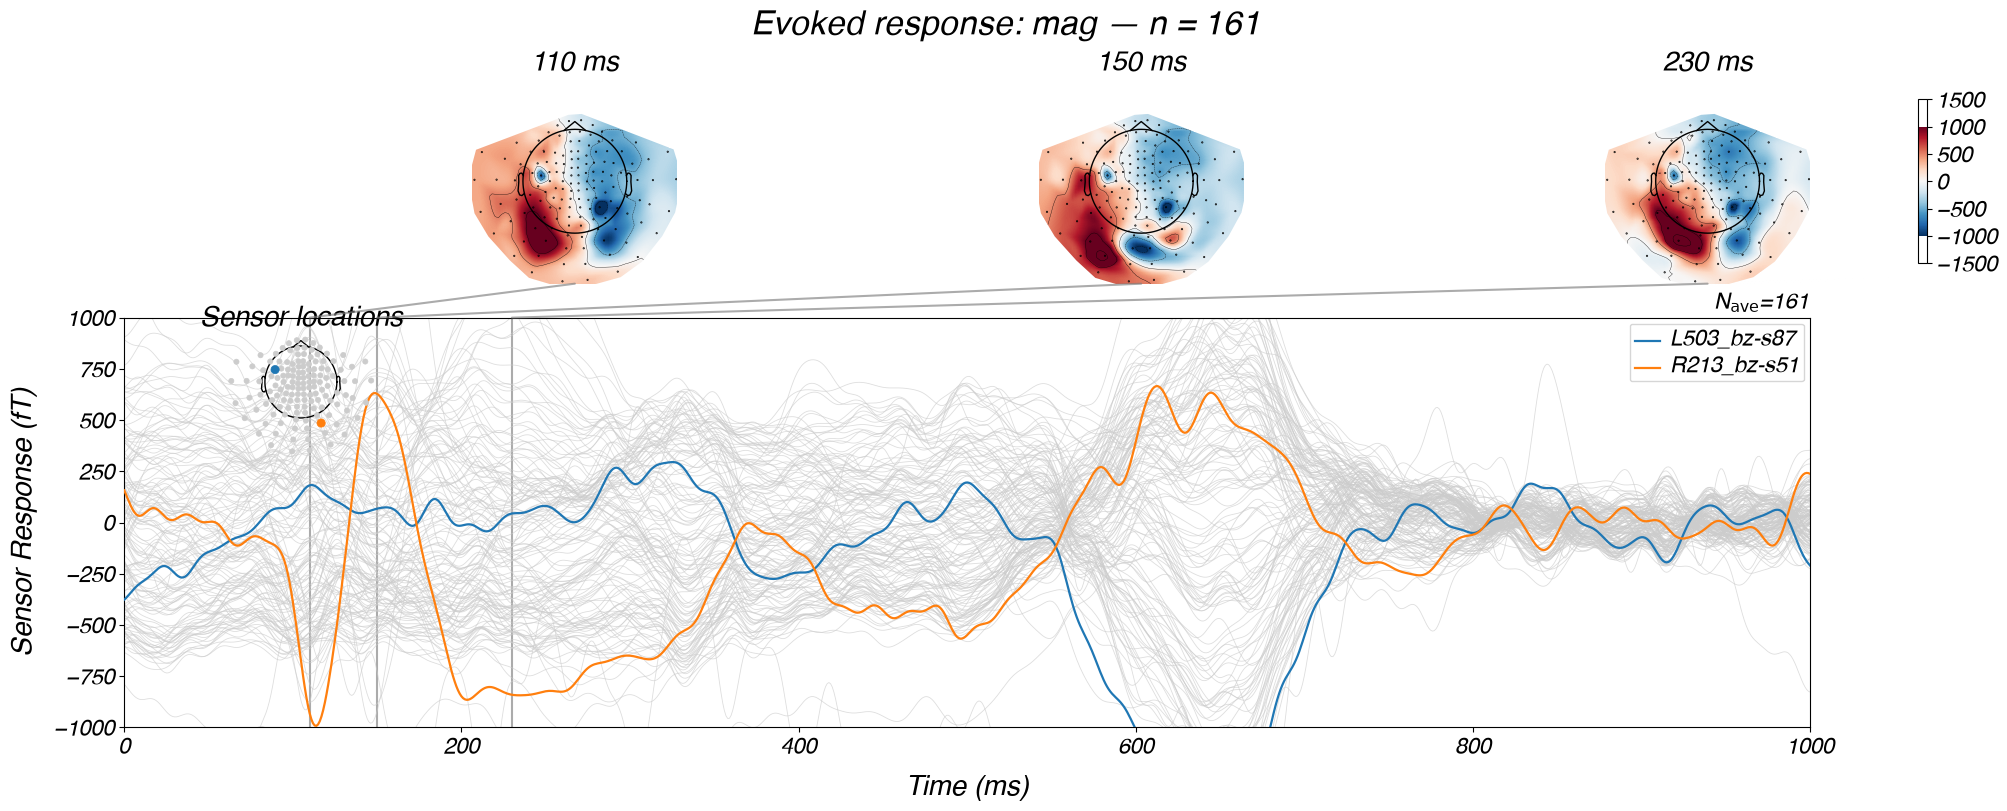

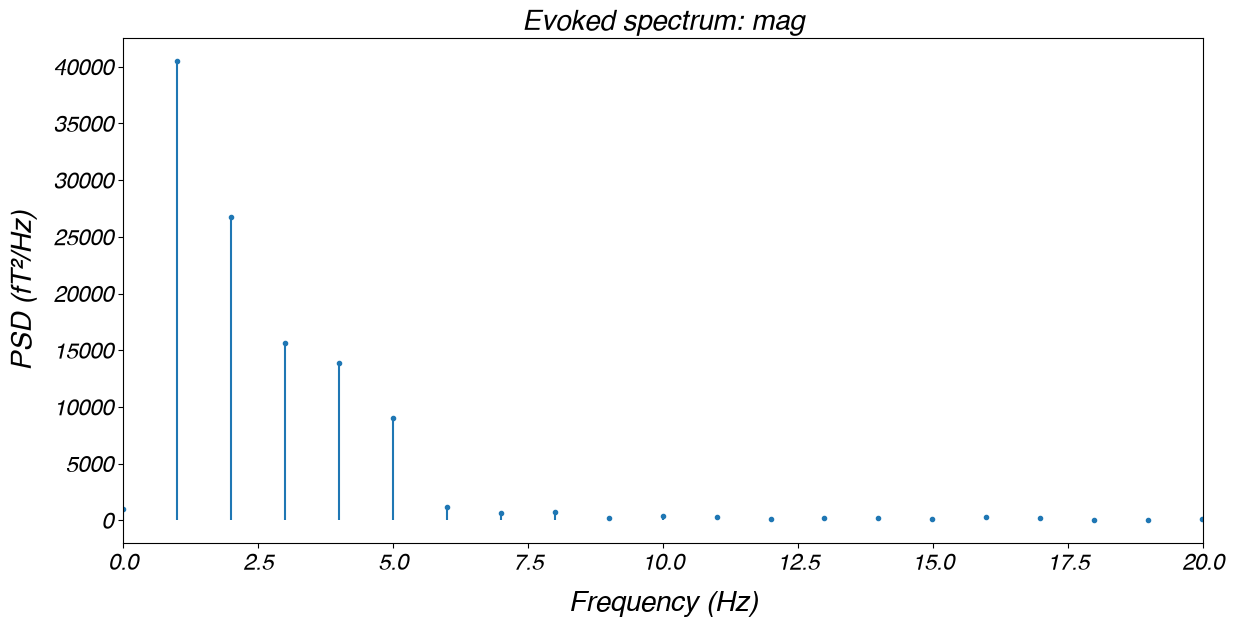

/Users/justin/proj/pgl/pgl/pglActionsMNE.py:303: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  # validate trialNum


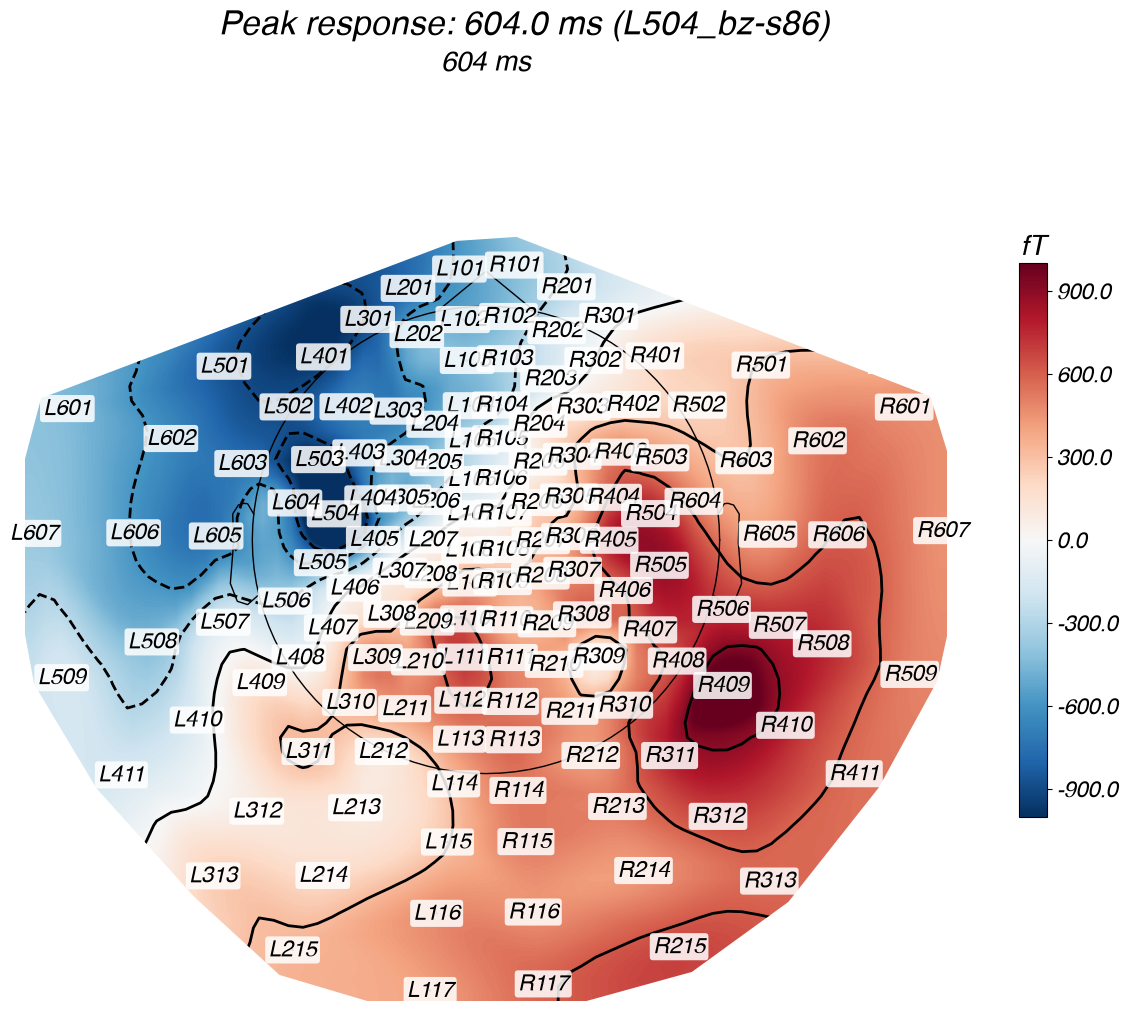

In [23]:
newSession = plotEvoked.run(session)
if newSession: session = newSession

---

Eyeblink rejection

---

In [ ]:
# fit and display ICA components
newSession = pglActionsMNE.ica.execute(session=session, chType='mag',nComponents=20)
if newSession: session = newSession

In [ ]:
# mark as bad based on ICA component from above and threshold in std
newSession = pglActionsMNE.markBlinks.execute(session=session, component=10, threshold=2)
if newSession: session = newSession

In [ ]:
# Create epochs, respecting the bads from the eyeblink (will fill time periods with NaN)
newSession = pglActionsMNE.createEpochsWithBads.execute(session=session)
if newSession: session = newSession

---

Plot evoked respecting Nans introduced by blink detection

---

In [ ]:
plotEvoked = pglActionsMNE.plotEvoked()
#plotEvoked.configure(set="grouped",label="things",minFreq=0,maxFreq=20,picks="L213")
#plotEvoked.configure(set="each",label="stimulus 010",picks='eeg')
#plotEvoked.configure(set="grouped",label="catch",minFreq=0,maxFreq=20,picks='eeg')
plotEvoked.configure(set="grouped",label="things",minFreq=0,maxFreq=20,picks='mag')
#mnePlotEvoked.configure(set="each",label="stimulus 021",minFreq=0,maxFreq=20,picks='eeg')

In [ ]:
newSession = plotEvoked.run(session=session)

---

Plot evoked each

---

In [ ]:
newSession = pglActionsMNE.plotEvokedEach.execute(session=session, set="each", yMin=-2000, yMax=2000, topoTime=150, highlightChannels=['L115', 'R213'],exportFig='~/Desktop/each.png')
if newSession: session = newSession

---

Downsample epochs

---

In [ ]:
newSession = pglActionsMNE.downsampleEpochs.execute(session=session, downsampleFrequency=200)
if newSession: session = newSession

In [ ]:
session.saveSession(description="fosters")

---

Compute NCSNR

---

In [ ]:
computeNCSNR = pglActionsMNE.computeNCSNR()
#computeNCSNR.configure(set="grouped",label="things",conditionIDColumn="code",chType="mag",channelName="L213_bz-s115")
#computeNCSNR.configure(set="grouped",label="things",conditionIDColumn="code",chType="mag")
computeNCSNR.configure(set="grouped",label="things",conditionIDColumn="code",chType="mag",channelName="L213_bz-s115", nTrials=12)


In [ ]:
newSession = computeNCSNR.run(session)
if newSession: session = newSession

---

Save session

---

In [ ]:
session.saveSession(description="ncsnr")

---

History

---

In [18]:
session.history(verbose=True)

=================================== Session ====================================
  Source checkpoint : 88
  Description       : filtered
  Runs              : 0
  Filesystem        : pglcheckpoint
  MEG/EEG data      : Attached

---------------------------- Experiment and subject ----------------------------
  Things MEG pilot / s0002
================================ action history ================================
0: loadFieldline ran at 21:34:19 10/13/2026 with status: SUCCESS duration: 10s
    filesystemPrefix = ''
    selectedPaths = ['/Users/justin/data/things/s0002/session_2026-09-09_meg-opm/20260909_122812_sub-S002_file-ThingsPilotRun01_raw.fif']
1: concatenate ran at 16:53:03 10/17/2026 with status: SUCCESS duration: 4s
    selectedRawFilenames = ['20260909_122812_sub-S002_file-ThingsPilotRun01_raw.fif']
2: filter ran at 16:53:10 10/17/2026 with status: SUCCESS duration: 16s
    highCutoff = 50.0
    lowCutoff = 0.5
    notch = True
    notchFrequency = 60.0
3: bads ran at 16:53

---

SCRATCH code

---

In [ ]:
session.mne.lookupSensor('L101')

Do spectrum on the evoked averages - take the mean of the 3000 trials in time domain and transform last
do it over 2 seconds - you should see nothing at 0.5Hz 

Compute how many seconds (in averages) and how many trials
Same yaxis
to look at sqrt(n) - compute 
Deflate the noise to compare to the number of trials

In [ ]:
%matplotlib qt
import mne
mne.viz.set_browser_backend("qt")
#session.mne.raw.plot(duration=20, n_channels=30, scalings="auto", block=True)
session.mne.raw.compute_psd().plot()

In [ ]:
# Check what maxwell sets in info
import numpy as np
from collections.abc import Mapping
from pprint import pformat


def format_value(value):
    # Keep potentially large arrays readable.
    with np.printoptions(threshold=20, edgeitems=3, precision=6):
        return pformat(value, width=100, sort_dicts=False)


def same_value(a, b):
    if isinstance(a, np.ndarray) or isinstance(b, np.ndarray):
        try:
            return np.array_equal(a, b, equal_nan=True)
        except TypeError:
            return np.array_equal(a, b)

    try:
        return bool(a == b)
    except (TypeError, ValueError):
        return False


def metadata_diff(before, after, path="info"):
    """Print changed, added, and removed metadata, including nested fields."""
    if isinstance(before, Mapping) and isinstance(after, Mapping):
        for key in sorted(set(before) | set(after), key=repr):
            child = f"{path}[{key!r}]"
            if key not in before:
                print(f"\nADDED {child}\n{format_value(after[key])}")
            elif key not in after:
                print(f"\nREMOVED {child}\n{format_value(before[key])}")
            else:
                metadata_diff(before[key], after[key], child)

    elif isinstance(before, (list, tuple)) and isinstance(after, (list, tuple)):
        for i in range(max(len(before), len(after))):
            child = f"{path}[{i}]"
            if i >= len(before):
                print(f"\nADDED {child}\n{format_value(after[i])}")
            elif i >= len(after):
                print(f"\nREMOVED {child}\n{format_value(before[i])}")
            else:
                metadata_diff(before[i], after[i], child)

    elif not same_value(before, after):
        print(f"\nCHANGED {path}")
        print(f"  BEFORE: {format_value(before)}")
        print(f"  AFTER:  {format_value(after)}")


raw = session.mne.raw
Lin=8
Lout=3
raw_preprocessed = mne.preprocessing.maxwell_filter(raw, origin=(0.,0.,0.), int_order=Lin, ext_order=Lout, calibration=None, coord_frame='meg', regularize='in', ignore_ref=True, bad_condition='error', mag_scale=100.0, extended_proj=(), verbose=None)  # just to get the info to indicate some Maxwell filtering was done etc.

metadata_diff(raw.info, raw_preprocessed.info)